# Chapter 3: Five exams instead of one

*Cross-validation · also searched as: k-fold cross validation, cross validation explained*

**By the end you can** show how one split's luck moves a score, run five folds by hand, read the
spread, and say what must stay inside the folds. All numbers here are invented.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


## Predict first

Twenty invented Kalpa customers. Hold out five as the exam and train on fifteen. If you deal a
different five into the exam, how much will the score move?

In [2]:
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
# Invented: visits in the last month and whether the customer bought in the sale.
crowd = pd.DataFrame({"visits": [0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 6, 6, 7, 7, 8, 9],
                      "bought": [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1]})
X, y = crowd[["visits"]], crowd["bought"]
rng = np.random.default_rng(7)
scores = []
for deal in range(5):
    exam = rng.choice(20, size=5, replace=False)
    teach = np.setdiff1d(np.arange(20), exam)
    m = LogisticRegression().fit(X.iloc[teach], y.iloc[teach])
    scores.append(m.score(X.iloc[exam], y.iloc[exam]))
print("accuracy on five different exams of five customers:", scores)

accuracy on five different exams of five customers: [0.6, 0.6, 0.8, 0.4, 0.6]


Same model, same customers, scores from the lowest to the highest of the list above. A five-customer
exam is mostly luck. Cross-validation stops trusting any one exam.

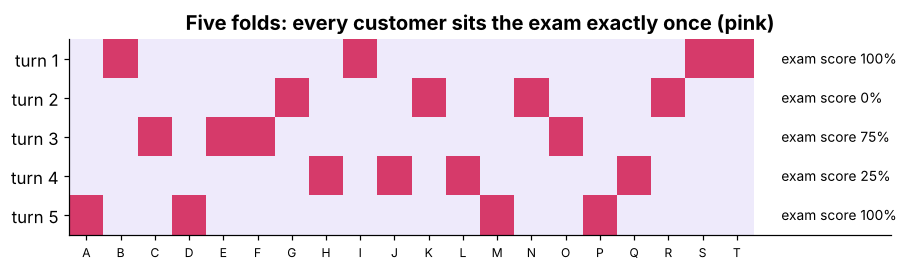

mean 0.60, spread (standard deviation) 0.41


In [3]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=0)
grid = np.zeros((5, 20))
fold_scores = []
for i, (teach, exam) in enumerate(kf.split(X)):
    grid[i, exam] = 1
    m = LogisticRegression().fit(X.iloc[teach], y.iloc[teach])
    fold_scores.append(m.score(X.iloc[exam], y.iloc[exam]))

fig, ax = plt.subplots(figsize=(8.5, 2.6))
ax.imshow(grid, cmap=plt.matplotlib.colors.ListedColormap(["#EEEAFB", ROSE]), aspect="auto")
for i, s in enumerate(fold_scores):
    ax.text(20.3, i, f"exam score {s:.0%}", va="center", fontsize=9)
ax.set_yticks(range(5)); ax.set_yticklabels([f"turn {i + 1}" for i in range(5)])
ax.set_xticks(range(20)); ax.set_xticklabels([chr(65 + i) for i in range(20)], fontsize=8)
ax.set_xlim(-0.5, 23.5); ax.set_title("Five folds: every customer sits the exam exactly once (pink)")
plt.tight_layout(); plt.show()
print(f"mean {np.mean(fold_scores):.2f}, spread (standard deviation) {np.std(fold_scores):.2f}")

In [4]:
check("every customer sat the exam exactly once", (grid.sum(axis=0) == 1).all())
check("five folds gave five scores", len(fold_scores) == 5)

PASS  every customer sat the exam exactly once
PASS  five folds gave five scores


## What must stay inside the folds?

Anything that learns from data. If you fill gaps or scale with the mean of all twenty customers before
the folds, every exam has helped set the number it is judged against.

In [5]:
teach, exam = next(kf.split(X))
print(f"mean visits, all 20 customers:        {X['visits'].mean():.2f}")
print(f"mean visits, the 16 teaching customers: {X.iloc[teach]['visits'].mean():.2f}")
print("The first number has seen the exam; the second has not. A Pipeline keeps the second.")
check("the two means differ, so the order of steps matters",
      round(X['visits'].mean(), 2) != round(X.iloc[teach]['visits'].mean(), 2))

mean visits, all 20 customers:        4.10
mean visits, the 16 teaching customers: 3.81
The first number has seen the exam; the second has not. A Pipeline keeps the second.
PASS  the two means differ, so the order of steps matters


## Carry this

| Rule | When it flips |
|---|---|
| Quote a cross-validated score as its mean with its spread | a sealed test set, used once, gives the final number (Friday) |
| Compare two models on the same folds, fold by fold | never compare one model's fold 1 with another's fold 3 |
| Shuffle the rows before cutting folds | when rows run in time order and the model will score the future: cut by time instead (Friday; search: time series split) |
| Every step that learns goes inside the folds | a step that learns nothing (a fixed formula) can sit outside |

What a cross-validated score estimates, in symbols, belongs to the tentative IITGN faculty session.